6 entries: ['Fixed Burg AR', 'BOB', 'EPN', 'PEAP', 'PHASTIMATE', 'PHASTPADDING']  | band=theta -> 'Theta'



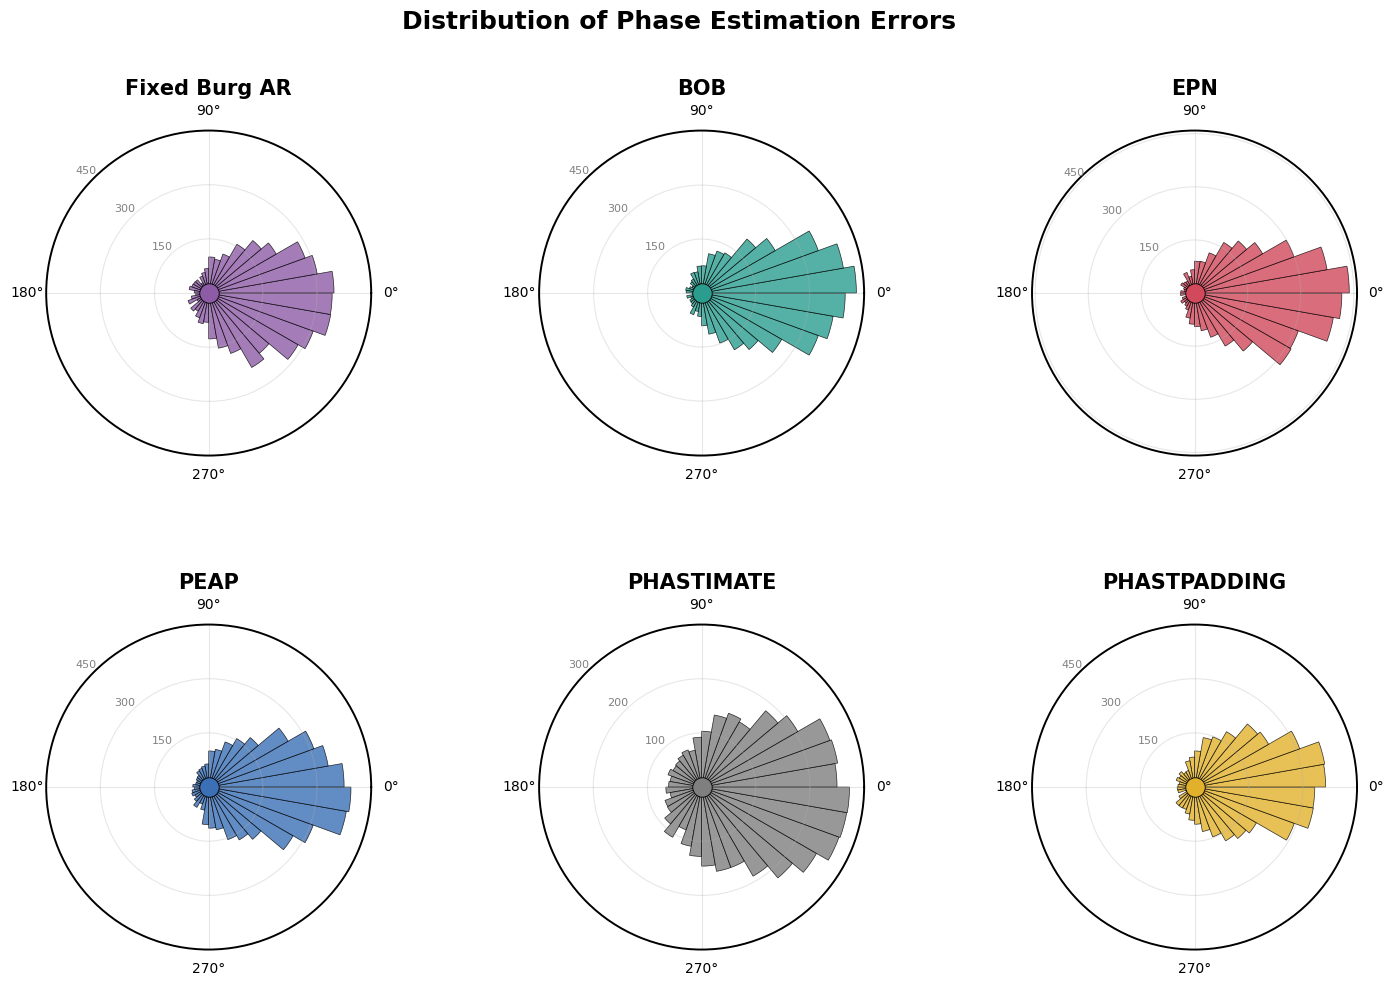

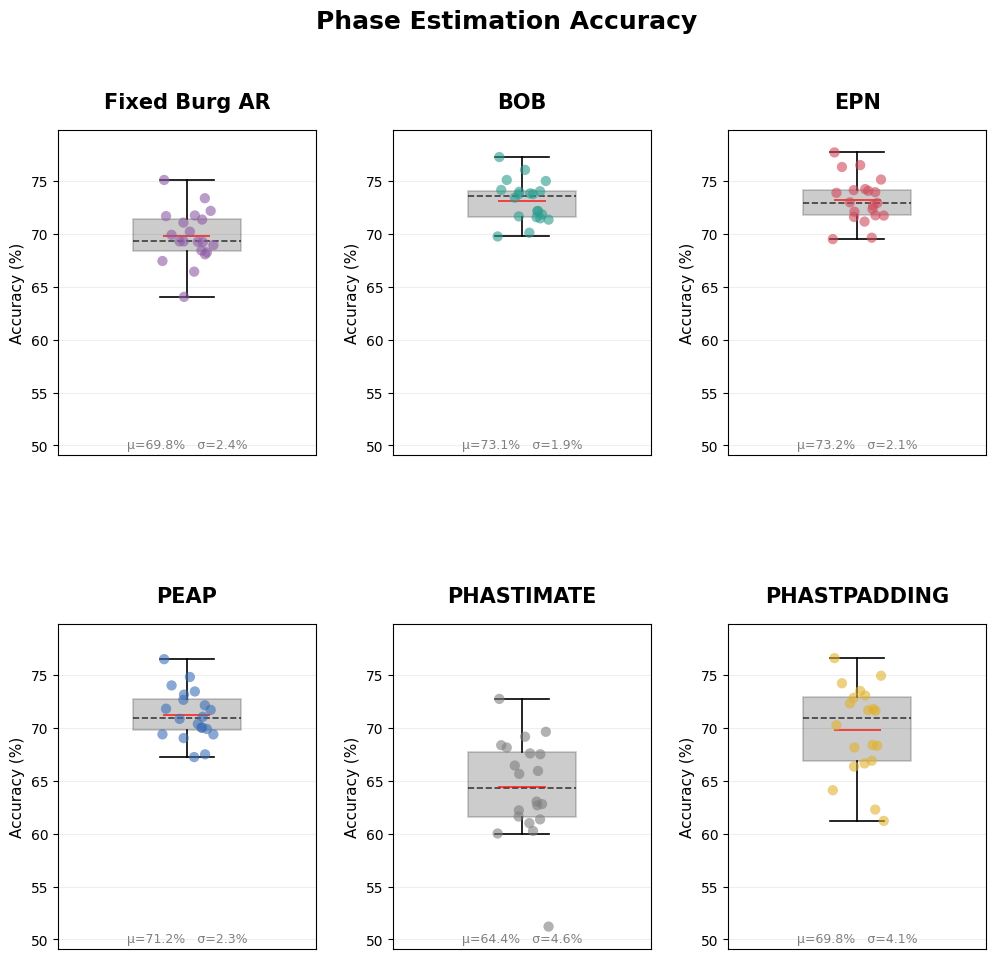

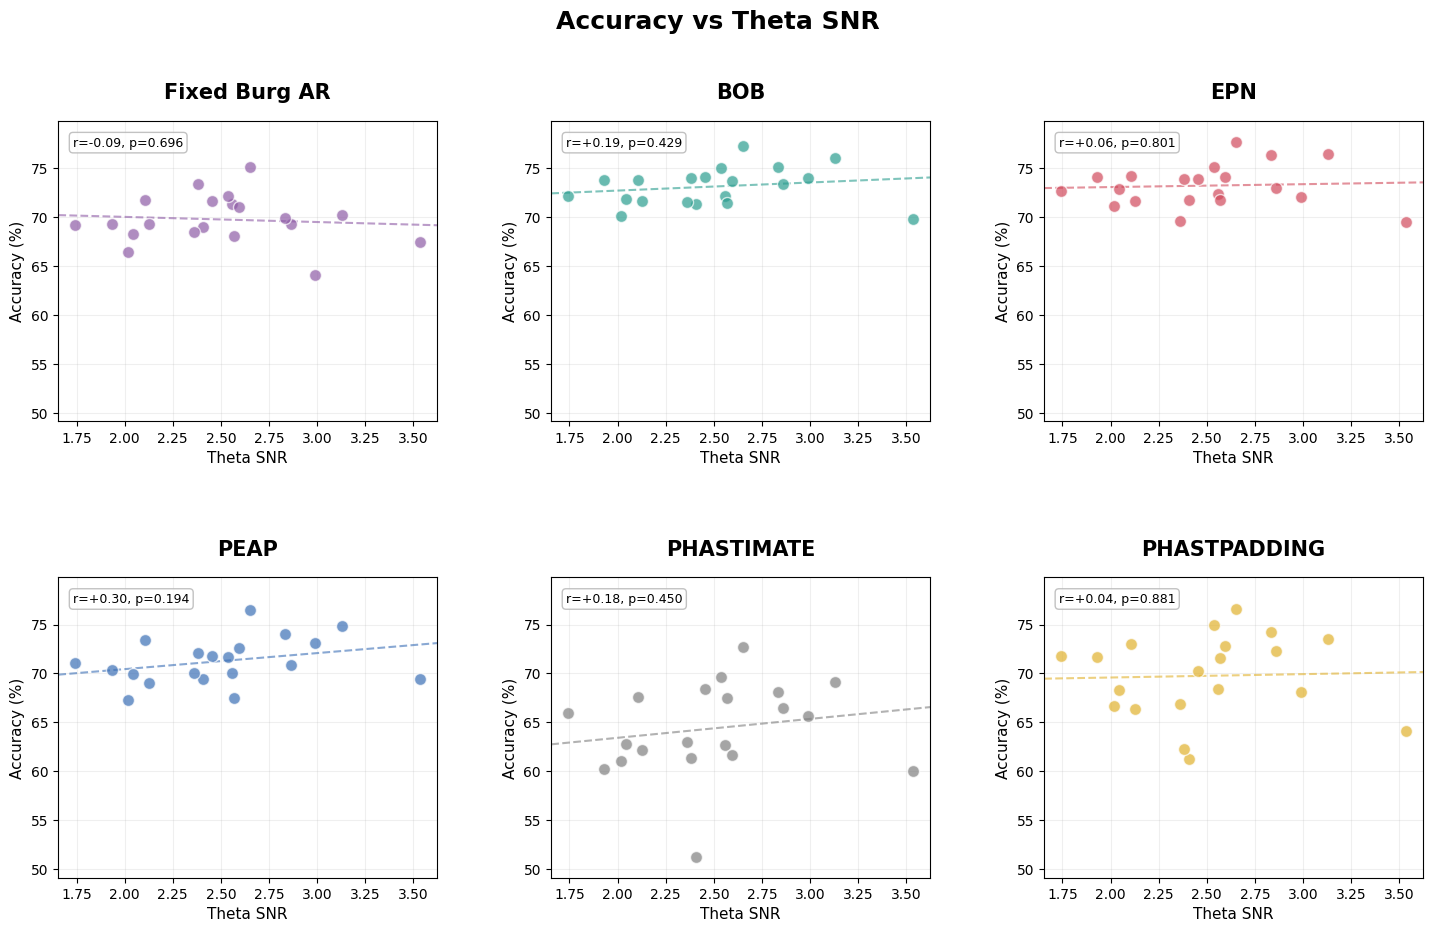

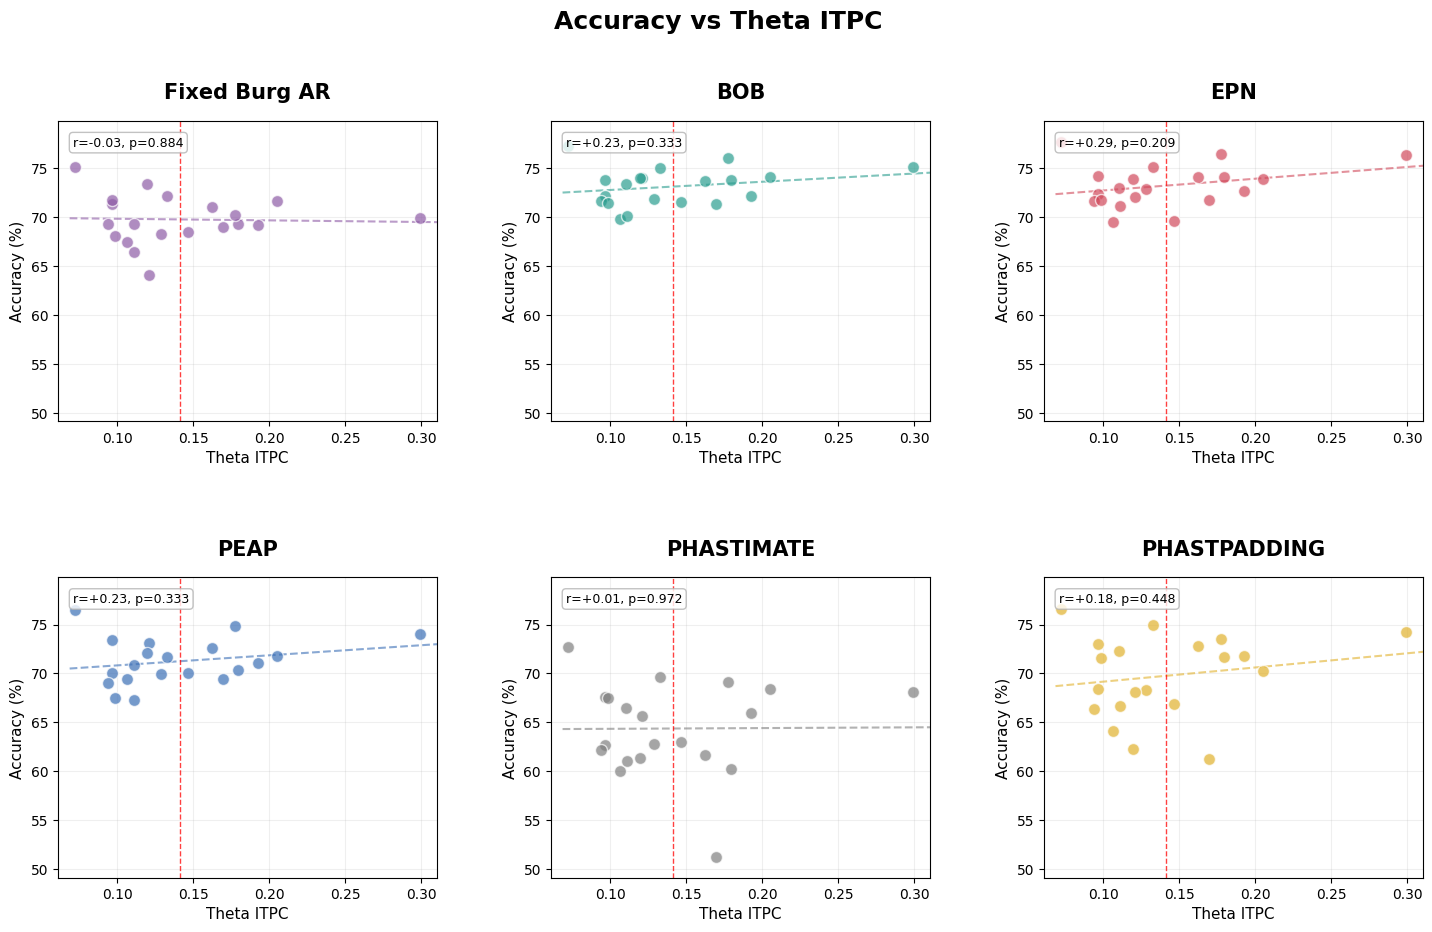

saved: polar_theta.png, accuracy_theta.png, snr_accuracy_theta.png, itpc_accuracy_theta.png -> /content/drive/MyDrive/RAIN_IRC/results/figures


In [ ]:
# ============================================================
# FIGURE EXPORT GROUPED BY TYPE  (one image per figure type; methods as panels)
#   polar_<band>.png         -> rose per method   (matches the template grid)
#   accuracy_<band>.png      -> accuracy box per method
#   snr_accuracy_<band>.png  -> SNR  vs accuracy per method
#   itpc_accuracy_<band>.png -> ITPC vs accuracy per method
#   BOB appears as two entries: "Fixed Burg AR" (default) and "BOB" (optimized).
#   Band 'alpha' is displayed as "Resting-State Mu" in axis labels.
# ============================================================
import os, glob, json, math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

RESULTS_DIR = '/content/drive/MyDrive/RAIN_IRC/results'
OUTDIR      = os.path.join(RESULTS_DIR, 'figures')
SHOW_INLINE = True
N_BINS      = 36
NCOLS       = 3            # columns in each grid (2 -> matches the 4-panel template column count)
os.makedirs(OUTDIR, exist_ok=True)

METHOD_COLOR = {
    'BOB':'#2A9D8F', 'EPN':'#D1495B', 'PEAP':'#3B6FB6',
    'PHASTIMATE':'#7F7F7F', 'PHASTPADDING':'#E1B12C',
}
COLOR_BOB_DEFAULT = '#8E5BA6'        # purple  (Fixed Burg AR)
DEFAULT_COLOR     = '#4C72B0'
SHOW_BEFORE_AFTER = {'BOB'}

# entry display order across the grid
ORDER = ['Fixed Burg AR', 'BOB', 'EPN', 'PEAP', 'PHASTIMATE', 'PHASTPADDING']

BAND_LABEL_OVERRIDE = {'Theta': 'Evoked Theta'}
def band_display(b): return BAND_LABEL_OVERRIDE.get(b, b.capitalize())
def band_slug(b): return ''.join(c if c.isalnum() else '_' for c in band_display(b)).strip('_').lower()

def canonical(name):
    u = str(name).upper()
    for k in METHOD_COLOR:
        if u.startswith(k): return k
    return name

def get_views(md, model):
    s0 = md['subjects'][0]; base = METHOD_COLOR.get(model, DEFAULT_COLOR)
    tuned = 'default_metrics_pooled' in s0
    if tuned and model in SHOW_BEFORE_AFTER:
        return [dict(mkey='default_metrics_pooled', ekey='default_errors_per_timepoint_rad', label='Fixed Burg AR', color=COLOR_BOB_DEFAULT),
                dict(mkey='opt_metrics_pooled',     ekey='opt_errors_per_timepoint_rad',     label='BOB',           color=base)]
    if tuned:
        mkey, ekey = 'opt_metrics_pooled', 'opt_errors_per_timepoint_rad'
    elif 'metrics_pooled' in s0:
        mkey, ekey = 'metrics_pooled', 'errors_per_timepoint_rad'
    else:
        raise KeyError(f"Unrecognized schema; subject keys: {list(s0)}")
    return [dict(mkey=mkey, ekey=ekey, label=model, color=base)]

def _find_key(s, suffix):
    for k in s:
        if k.endswith(suffix): return k
    raise KeyError(suffix)

def load_models(results_dir, outdir):
    out = []
    for p in sorted(glob.glob(os.path.join(results_dir, '**', '*.json'), recursive=True)):
        if os.path.abspath(outdir) in os.path.abspath(p): continue
        with open(p) as f: d = json.load(f)
        out.append((canonical(d.get('model') or os.path.basename(os.path.dirname(p))), d))
    return out

def pooled_errors(md, ekey):
    chunks = [np.asarray(a, float) for s in md['subjects'] for a in s[ekey].values()]
    return np.concatenate(chunks) if chunks else np.array([])

def per_subject_acc(md, mkey):
    return np.array([s[mkey]['acc'] for s in md['subjects']])

def signal_props(md, first_mkey):
    s0 = md['subjects'][0]
    sk, ik = _find_key(s0, '_snr'), _find_key(s0, '_itpc_mean')
    snr  = np.array([s[sk] for s in md['subjects']])
    itpc = np.array([s[ik] for s in md['subjects']])
    band = sk.rsplit('_', 1)[0].split('_')[-1]
    n_tp = len(md['config'].get('eval_times_s', [])) or len(s0[_find_key(s0, '_itpc_per_timepoint')])
    trials = [s[first_mkey]['n_samples'] / max(n_tp, 1) for s in md['subjects']]
    return snr, itpc, band, int(np.median(trials)), [s['name'] for s in md['subjects']]

def _pad(v, f=0.05):
    span = np.ptp(v) or 1e-9
    return v.min() - f*span, v.max() + f*span

# ---------- panel drawers ----------
def draw_polar(ax, errors_rad, color, title):
    edges = np.linspace(-np.pi, np.pi, N_BINS + 1)
    counts, _ = np.histogram(errors_rad, bins=edges)
    centers = (edges[:-1] + edges[1:]) / 2
    ax.bar(centers, counts, width=2*np.pi/N_BINS, bottom=0, color=color, alpha=0.8,
           edgecolor='black', linewidth=0.5)
    mdir = np.angle(np.mean(np.exp(1j*errors_rad)))
    ax.plot(mdir, 0, 'o', color=color, markersize=14, markeredgecolor='black', markeredgewidth=0.6, zorder=5)
    ax.set_theta_zero_location('E'); ax.set_theta_direction(1)
    ax.set_thetagrids([0, 90, 180, 270], ['0°', '90°', '180°', '270°'])
    mx = int(max(counts)) if len(counts) else 1
    step = max(1, int(np.ceil(mx/3/50)*50)); ticks = np.arange(step, mx + step, step)
    ax.set_rticks(ticks); ax.set_rlabel_position(135); ax.set_yticklabels([])
    for tk in ticks:
        ax.text(np.radians(135), tk + step*0.2, f'{int(tk)}', fontsize=8, color='gray', ha='center', va='center')
    ax.grid(True, alpha=0.3); ax.spines['polar'].set_linewidth(1.4)
    ax.set_title(title, fontsize=15, fontweight='bold', pad=26)

def draw_box(ax, accs, color, ylim, title):
    rng = np.random.default_rng(42)
    ax.boxplot([accs], positions=[0], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor='black', alpha=0.2, linewidth=1.2),
               medianprops=dict(color='black', alpha=0.7, linewidth=1.2, linestyle='--'),
               whiskerprops=dict(color='black', linewidth=1.2),
               capprops=dict(color='black', linewidth=1.2), showfliers=False)
    ax.scatter(rng.uniform(-0.13, 0.13, len(accs)), accs, c=color, s=55, alpha=0.6, edgecolors='none', zorder=5)
    m, sd = float(np.mean(accs)), float(np.std(accs))
    ax.hlines(m, -0.11, 0.11, color='red', linewidth=1.2, alpha=0.8, zorder=4)
    ax.text(0, ylim[0] + 0.4, f'μ={m:.1f}%   σ={sd:.1f}%', ha='center', va='bottom', fontsize=9, color='gray')
    ax.set_xticks([]); ax.set_ylabel('Accuracy (%)', fontsize=11)
    ax.set_title(title, fontsize=15, fontweight='bold', pad=16)
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(*ylim); ax.grid(True, axis='y', alpha=0.2)

def draw_scatter(ax, x, accs, color, xlabel, xlim, ylim, names, add_chance, chance_n, title):
    ax.scatter(x, accs, c=color, s=75, alpha=0.7, edgecolors='white', linewidths=1, zorder=3)
    if np.std(x) > 0:
        z = np.polyfit(x, accs, 1); xf = np.linspace(x.min()*0.95, x.max()*1.05, 50)
        ax.plot(xf, np.polyval(z, xf), '--', color=color, alpha=0.6, linewidth=1.5)
        r, p = pearsonr(x, accs)
    else:
        r, p = np.nan, np.nan
    if add_chance:
        ax.axvline(1.0/np.sqrt(chance_n), color='red', lw=1, ls='--', alpha=0.75)
    ax.text(0.04, 0.95, f'r={r:+.2f}, p={p:.3f}', transform=ax.transAxes, fontsize=9,
            va='top', ha='left', bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.8))
    ax.set_xlabel(xlabel, fontsize=11); ax.set_ylabel('Accuracy (%)', fontsize=11)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.grid(True, alpha=0.2)
    ax.set_title(title, fontsize=15, fontweight='bold', pad=16)

def grid_dims(n):
    ncols = NCOLS if n > 4 else 2
    return ncols, math.ceil(n / ncols)

def new_grid(n, cell_w, cell_h, polar=False):
    ncols, nrows = grid_dims(n)
    fig = plt.figure(figsize=(cell_w*ncols, cell_h*nrows + 0.5))
    gs = gridspec.GridSpec(nrows, ncols, figure=fig, left=0.06, right=0.97,
                           top=0.85, bottom=0.07, wspace=0.30, hspace=0.52)
    axes = []
    for i in range(n):
        r, c = divmod(i, ncols)
        axes.append(fig.add_subplot(gs[r, c], projection='polar' if polar else None))
    return fig, axes

def main():
    models = load_models(RESULTS_DIR, OUTDIR)
    entries = []
    for model, md in models:
        for v in get_views(md, model):
            entries.append({**v, 'md': md})
    entries.sort(key=lambda e: ORDER.index(e['label']) if e['label'] in ORDER else 999)
    band = signal_props(entries[0]['md'], entries[0]['mkey'])[2]
    bd, slug = band_display(band), band_slug(band)
    print(f"{len(entries)} entries: {[e['label'] for e in entries]}  | band={band} -> '{bd}'\n")

    # global axis ranges (shared across panels where it aids comparison)
    all_acc = np.concatenate([per_subject_acc(e['md'], e['mkey']) for e in entries])
    ypad = max(2.0, 0.08*(np.ptp(all_acc) or 1))
    ylim = (all_acc.min() - ypad, all_acc.max() + ypad)
    snr0, itpc0, _, chance_n, _ = signal_props(entries[0]['md'], entries[0]['mkey'])
    snr_lim, itpc_lim = _pad(snr0), _pad(itpc0)

    saved = []
    def finish(fig, title, fname):
        fig.suptitle(title, fontsize=18, fontweight='bold', y=0.965)
        fig.savefig(os.path.join(OUTDIR, fname), dpi=300, bbox_inches='tight')
        if SHOW_INLINE: plt.show()
        plt.close(fig); saved.append(fname)

    # ---- POLAR ----
    fig, axes = new_grid(len(entries), 5.0, 5.0, polar=True)
    for ax, e in zip(axes, entries):
        draw_polar(ax, pooled_errors(e['md'], e['ekey']), e['color'], e['label'])
    finish(fig, 'Distribution of Phase Estimation Errors', f'polar_{slug}.png')

    # ---- ACCURACY ----
    fig, axes = new_grid(len(entries), 3.4, 5.0)
    for ax, e in zip(axes, entries):
        draw_box(ax, per_subject_acc(e['md'], e['mkey']), e['color'], ylim, e['label'])
    finish(fig, 'Phase Estimation Accuracy', f'accuracy_{slug}.png')

    # ---- SNR vs ACC ----
    fig, axes = new_grid(len(entries), 5.0, 4.6)
    for ax, e in zip(axes, entries):
        snr, _, _, cn, names = signal_props(e['md'], e['mkey'])
        draw_scatter(ax, snr, per_subject_acc(e['md'], e['mkey']), e['color'],
                     f'{bd} SNR', snr_lim, ylim, names, False, cn, e['label'])
    finish(fig, f'Accuracy vs {bd} SNR', f'snr_accuracy_{slug}.png')

    # ---- ITPC vs ACC ----
    fig, axes = new_grid(len(entries), 5.0, 4.6)
    for ax, e in zip(axes, entries):
        _, itpc, _, cn, names = signal_props(e['md'], e['mkey'])
        draw_scatter(ax, itpc, per_subject_acc(e['md'], e['mkey']), e['color'],
                     f'{bd} ITPC', itpc_lim, ylim, names, True, cn, e['label'])
    finish(fig, f'Accuracy vs {bd} ITPC', f'itpc_accuracy_{slug}.png')

    print('saved:', ', '.join(saved), '->', OUTDIR)

main()

In [ ]:
import json
import numpy as np
import pandas as pd

INCLUDE_PER_TIMEPOINT = True          # set False to skip the per-timepoint CSV
OUT_DIR = '/content/drive/MyDrive/RAIN_IRC/results/tables'
SHOW_BEFORE_AFTER = {'BOB'}           # BOB gets default + opt rows

# labels here must match what conditions_for() produces:
#   BOB -> 'BOB (default)' and 'BOB (opt)';  others -> bare method name
PREFERRED_ORDER = ['BOB (default)', 'BOB (opt)',
                   'EPN', 'PEAP', 'PHASTIMATE', 'PHASTPADDING']

In [ ]:
# ---- mount Drive + locate each method's JSON ----
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Drive mount skipped:', e)

import os, glob

BASE      = '/content/drive/MyDrive/RAIN_IRC/results'   # <<< your results folder
METHODS   = ['BOB','EPN','PEAP','PHASTIMATE','PHASTPADDING']
BAND_HINT = None        # set 'alpha' or 'theta' if a method folder has both; None = take first match

_all = glob.glob(os.path.join(BASE, '**', '*.json'), recursive=True)
def _find(method):
    c = [p for p in _all if method.lower() in p.lower() and p.lower().endswith('.json')]
    if BAND_HINT:
        c = [p for p in c if BAND_HINT.lower() in p.lower()] or c
    return c

RESULTS, missing = {}, []
for m in METHODS:
    hits = _find(m)
    RESULTS[m] = hits[0] if hits else missing.append(m)

print(f'searched {BASE}  ({len(_all)} json found)')
for m, p in RESULTS.items():
    print(f'  {m:13s} -> {p}')
if missing:
    raise FileNotFoundError(
        f'No JSON for {missing}. Check BASE, or list with: '
        f'glob.glob("{BASE}/**/*.json", recursive=True)')
def load_json(path):
    if os.path.isdir(path):
        hits = sorted(glob.glob(os.path.join(path, '*.json')))
        if not hits: raise FileNotFoundError(f'no .json in {path}')
        path = hits[0]
    with open(path) as f: return json.load(f)

def detect_band(data):
    keys = data['subjects'][0].keys()
    for b in ('alpha','theta','beta','mu','delta','gamma'):
        if f'{b}_snr' in keys or f'{b}_itpc_mean' in keys: return b
    return '?'

def conditions_for(name, data):
    s0 = data['subjects'][0]; tuned = 'opt_metrics_pooled' in s0
    if tuned:
        if name in SHOW_BEFORE_AFTER:
            return [(f'{name} (default)','default_metrics_pooled','default_metrics_per_timepoint','default_errors_per_timepoint_rad'),
                    (f'{name} (opt)',    'opt_metrics_pooled',    'opt_metrics_per_timepoint',    'opt_errors_per_timepoint_rad')]
        return [(name,'opt_metrics_pooled','opt_metrics_per_timepoint','opt_errors_per_timepoint_rad')]
    return [(name,'metrics_pooled','metrics_per_timepoint','errors_per_timepoint_rad')]

POOLED = ['mace','acc','plv','csd','bias']          # circular metrics in each *_metrics_pooled dict
def sig(s, band, key, default=np.nan):
    return s.get(f'{band}_{key}', default)

per_subject_rows, per_tp_rows, summary_rows = [], [], []
band = '?'
for name, path in RESULTS.items():
    data = load_json(path); band = detect_band(data)
    tps  = data['config']['eval_times_s']
    for label, mk, mtk, ek in conditions_for(name, data):
        subs = data['subjects']
        for s in subs:                                          # per-subject wide rows
            row = dict(model=label, subject=s.get('name'), best_ch=s.get('best_ch'),
                       n_trials=s.get('n_trials'),
                       snr=sig(s,band,'snr'), itpc=sig(s,band,'itpc_mean'), peak_hz=sig(s,band,'peak_hz'))
            for m in POOLED: row[m] = s[mk].get(m)
            row['n_samples'] = s[mk].get('n_samples')
            per_subject_rows.append(row)
            if INCLUDE_PER_TIMEPOINT:                           # per-timepoint long rows
                itpc_tp = s.get(f'{band}_itpc_per_timepoint', {})
                for t in tps:
                    d = s[mtk][str(t)]
                    rec = dict(model=label, subject=s.get('name'), t_s=t, itpc=itpc_tp.get(str(t), np.nan))
                    for m in POOLED + ['n_samples']: rec[m] = d.get(m)
                    per_tp_rows.append(rec)
        err = np.concatenate([np.asarray(s[ek][str(t)],float) for s in subs for t in tps])  # group circular
        z = np.mean(np.exp(1j*err)); R = np.abs(z)
        summary_rows.append(dict(model=label, n=len(subs), band=band,
            R=R, bias_circ=np.degrees(np.angle(z)),
            csd_circ=np.degrees(np.sqrt(-2*np.log(R))), angdev=np.degrees(np.sqrt(2*(1-R)))))

ps = pd.DataFrame(per_subject_rows); ps['absbias'] = ps['bias'].abs()
grp = pd.DataFrame(summary_rows)

METRICS = ['mace','acc','plv','csd','bias','absbias','snr','itpc','peak_hz','n_trials','n_samples']
agg = ps.groupby('model')[METRICS].agg(['mean','std','median'])
agg = agg.reindex([m for m in PREFERRED_ORDER if m in agg.index])

def order(d, col='model'):
    d = d.copy(); d['__o'] = d[col].map(lambda m: PREFERRED_ORDER.index(m) if m in PREFERRED_ORDER else 999)
    return d.sort_values('__o').drop(columns='__o')
grp = order(grp).reset_index(drop=True)

LABELS = {'mace':'MACE (°)','acc':'Accuracy (%)','plv':'PLV','csd':'CSD (°)','bias':'Bias (°)',
          'absbias':'|Bias| (°)','snr':'SNR','itpc':'ITPC','peak_hz':'Peak (Hz)',
          'n_trials':'n trials','n_samples':'n samples'}
DEC = {'mace':2,'acc':2,'plv':3,'csd':2,'bias':2,'absbias':2,'snr':3,'itpc':3,'peak_hz':2,'n_trials':0,'n_samples':0}
disp = {}
for m in METRICS:
    disp[LABELS[m]] = {meth: f"{agg.loc[meth,(m,'mean')]:.{DEC[m]}f} ± {agg.loc[meth,(m,'std')]:.{DEC[m]}f}"
                       for meth in agg.index}
disp_df = pd.DataFrame(disp).T[list(agg.index)]
gmap = grp.set_index('model')
for lbl, col, d in [('Bias circ (°)','bias_circ',2),('CSD circ (°)','csd_circ',2),
                    ('Ang dev (°)','angdev',2),('R (pooled)','R',3)]:
    disp_df.loc[lbl] = {meth: f"{gmap.loc[meth,col]:.{d}f}" for meth in agg.index}

pd.set_option('display.max_columns', None, 'display.width', 200)
print(f'\nCOMPLETE METRIC TABLE   (band = {band}, n = {grp["n"].iloc[0]} subjects)')
print('per-subject metrics shown as mean ± SD;  *_circ / R = group-level circular over all pooled errors\n')
print(disp_df.to_string())

os.makedirs(OUT_DIR, exist_ok=True)
flat = agg.copy(); flat.columns = [f'{m}_{s}' for m,s in flat.columns]
flat = flat.merge(grp.set_index('model')[['n','R','bias_circ','csd_circ','angdev']], left_index=True, right_index=True)
flat.round(4).to_csv(os.path.join(OUT_DIR, f'metric_summary_{band}.csv'))
order(ps).round(5).to_csv(os.path.join(OUT_DIR, f'per_subject_{band}.csv'), index=False)
if INCLUDE_PER_TIMEPOINT:
    order(pd.DataFrame(per_tp_rows)).round(5).to_csv(os.path.join(OUT_DIR, f'per_timepoint_{band}.csv'), index=False)
print(f'\nsaved: metric_summary_{band}.csv, per_subject_{band}.csv'
      + (f', per_timepoint_{band}.csv' if INCLUDE_PER_TIMEPOINT else ''))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
searched /content/drive/MyDrive/RAIN_IRC/results  (5 json found)
  BOB           -> /content/drive/MyDrive/RAIN_IRC/results/BOB_onset/bob_theta_results.json
  EPN           -> /content/drive/MyDrive/RAIN_IRC/results/EPN_onset/epn_theta_results.json
  PEAP          -> /content/drive/MyDrive/RAIN_IRC/results/PEAP_onset/peap_theta_results.json
  PHASTIMATE    -> /content/drive/MyDrive/RAIN_IRC/results/PHASTIMATE_onset/phastimate_theta_results.json
  PHASTPADDING  -> /content/drive/MyDrive/RAIN_IRC/results/PHASTPADDING_FAITHFUL_onset/phastpadding_faithful_theta_results.json

COMPLETE METRIC TABLE   (band = theta, n = 20 subjects)
per-subject metrics shown as mean ± SD;  *_circ / R = group-level circular over all pooled errors

               BOB (default)      BOB (opt)            EPN           PEAP      PHASTIMATE   PHASTPADDING
MACE (°)        54.44 ± 4.47   48

In [ ]:
import json, numpy as np

# ---- config ----
BOB_JSON  = '/content/drive/MyDrive/RAIN_IRC/results/BOB_onset/bob_theta_results.json'
CONDITION = 'opt'        # 'opt' = Gated/tuned  ;  'default' = Fixed Burg AR
SORT_NUMERIC = True      # order rows by numeric subject id (else keep json order)

PKEY = {'opt': 'best_params',          'default': 'default_params'}[CONDITION]
MKEY = {'opt': 'opt_metrics_pooled',   'default': 'default_metrics_pooled'}[CONDITION]
COND_LABEL = {'opt': 'Gated', 'default': 'Fixed Burg AR'}[CONDITION]

with open(BOB_JSON) as f:
    d = json.load(f)
subs = d['subjects']

def subj_num(s):
    digits = ''.join(c for c in s['name'] if c.isdigit())
    return int(digits) if digits else 0
if SORT_NUMERIC:
    subs = sorted(subs, key=subj_num)

# caption stats = group means over the chosen condition
mace = np.mean([s[MKEY]['mace'] for s in subs])
plv  = np.mean([s[MKEY]['plv']  for s in subs])
print(f'% caption -> {COND_LABEL} (MACE: {mace:.1f}\\textdegree, PLV: {plv:.3f})')
print(f'% n = {len(subs)} subjects\n')

# body rows: N & AR & Ctx(s) & Band(Hz) & Pad
for i, s in enumerate(subs, start=1):
    p   = s[PKEY]
    ar  = int(round(p['ar_order']))
    ctx = p['context_s']
    lo, hi = p['filt_low'], p['filt_high']
    pad = int(round(p['hilbert_pad']))
    print(f'{i:<2} & {ar:>2} & {ctx:.1f} & {lo:.1f}--{hi:.1f} & {pad:>3} \\\\')

% caption -> Gated (MACE: 48.4\textdegree, PLV: 0.561)
% n = 20 subjects

1  & 24 & 1.3 & 4.4--7.4 & 100 \\
2  & 61 & 0.9 & 4.7--7.2 &  30 \\
3  & 83 & 1.6 & 5.0--7.1 & 100 \\
4  & 100 & 0.8 & 4.5--7.0 &  65 \\
5  & 61 & 0.8 & 5.1--7.2 &  30 \\
6  & 74 & 0.8 & 4.5--7.6 & 100 \\
7  & 24 & 1.6 & 4.2--7.6 & 100 \\
8  & 24 & 0.8 & 4.3--7.5 & 100 \\
9  & 41 & 1.6 & 4.8--7.5 & 100 \\
10 & 24 & 0.8 & 4.9--7.0 &  30 \\
11 & 60 & 1.0 & 5.0--7.2 & 100 \\
12 & 24 & 1.5 & 5.0--7.0 &  60 \\
13 & 24 & 0.8 & 4.6--8.0 &  95 \\
14 & 24 & 0.9 & 4.6--7.3 &  30 \\
15 & 52 & 1.6 & 4.8--7.4 & 100 \\
16 & 53 & 1.6 & 4.8--7.5 & 100 \\
17 & 24 & 1.5 & 4.3--7.2 & 100 \\
18 & 100 & 0.8 & 4.4--8.0 &  30 \\
19 & 24 & 1.2 & 4.3--7.5 &  63 \\
20 & 24 & 0.8 & 4.7--7.2 & 100 \\
